<div dir="rtl" style="text-align:right">

# نوت‌بوک ۰۳ — بخش ۲: مقایسه روش‌ها (آشکارساز و مکان‌یاب)

این نوت‌بوک **خروجی‌های** `run_part2_detector.py` و `run_part2_localiser.py` را می‌خواند و همه چیزی را که بخش ۲ گزارش لازم دارد می‌سازد: جدول «روش، ورودی، داده آموزش، معیار انتخاب، نتایج، محدودیت‌ها»، مقایسه‌های کنترل‌شده (ablation)، اثر طول پنجره، اثر کانال‌های اضافه، اثر داده مصنوعی، مبناهای غیرعصبی و ورودی بخش ۳ (انتخاب روش نهایی). آموزش مدل‌ها در اسکریپت‌ها می‌ماند و این‌جا فقط تحلیل و نمایش انجام می‌شود، پس به `pipeline.py` نیازی نیست.

**فایل‌های لازم**

| فایل | منبع | وضعیت |
| --- | --- | --- |
| `artifacts/part2_detector_designs.csv`، `…_windows.csv`، `…_baselines.csv` | `run_part2_detector.py` (حالت `all`) | الزامی |
| `artifacts/part2_detector_designs2.csv`، `…_designs3.csv` | حالت‌های `N2` و `N3` همان اسکریپت | اختیاری ولی توصیه‌شده (طرح‌های N2 و N3 را وارد می‌کند) |
| `artifacts/part2_localiser_designs.csv` | `run_part2_localiser.py` | الزامی برای بخش ۹ |
| `artifacts/leaks_with_clusters.csv`، `cluster_info.json`، `clusters.csv`، `historical_2018/labels.csv` | بخش ۱ و داده | الزامی |
| `artifacts/part2_detector_seeds.csv` | اسکریپت پیشنهادی بخش ۴ | اختیاری (کف نویز آموزش) |
| `artifacts/pred_det_*.npy` | پیشنهاد بخش ۱۰ | اختیاری (ROC و بازه اطمینان) |

| بخش | محتوا | خواسته صورت پروژه |
| --- | --- | --- |
| ۱ | بارگذاری و پارامترهای از پیش تعیین‌شده | — |
| ۲ | پروتکل و بررسی تفکیک زمانی | «قاعده تفکیک» و جلوگیری از نشت داده |
| ۳ | نمای کلی طرح‌های آشکارساز | جدول روش و نتایج |
| ۴ | کف نویز آموزش (چند seed) | معتبر بودن تفاوت‌ها |
| ۵ | مقایسه‌های کنترل‌شده | خط پایه، سفیدسازی، جریان و تراز، AMR، داده مصنوعی |
| ۶ | طول پنجره ۱ تا ۲۴ ساعت | «طول پنجره را از ۱ تا ۲۴ ساعت تغییر دهید» |
| ۷ | مبناهای غیرعصبی | «یک روش پایه غیرعصبی» |
| ۸ | انتخاب آشکارساز با قاعده از پیش تعیین‌شده | معیارهای انتخاب |
| ۹ | مکان‌یاب | مقایسه با و بدون داده مصنوعی، مبنای غیرعصبی |
| ۱۰ | ROC و بازه اطمینان (اختیاری) | پیش‌بینی عملکرد با بازه |
| ۱۱ | جدول نهایی گزارش بخش ۲ | خروجی تحویلی بخش ۲ |
| ۱۲ | فرض‌ها و آنچه تصمیم را تغییر می‌دهد | ورودی بخش‌های ۳ و ۴ |

برچسب نمودارها انگلیسی است و شرح فارسی را زیر شکل در گزارش بیاورید. اعداد را از اجرای واقعی خودتان بخوانید؛ سلول‌های «چطور بخوانیم» شرطی نوشته شده‌اند.

</div>

<div dir="rtl" style="text-align:right">

## ۱. بارگذاری و پارامترهای از پیش تعیین‌شده

سه پارامتر زیر **قبل از دیدن نتایج** تعیین می‌شوند و بعد از دیدن نتیجه تغییر نکنند، وگرنه قاعده انتخاب (بخش ۸) فقط توجیه نتیجه‌ای می‌شود که از قبل دیده‌اید:

- `FA_BUDGET`: بیشینه «روز هشدار کاذب به ازای ۳۰ روز» که می‌پذیرید؛
- `DEFAULT_NOISE`: تفاوتی که در نبود اجرای چند-seed تفاوت واقعی حساب نمی‌شود؛
- `TRAIN_END`: همان تاریخ جداکننده در اسکریپت‌ها.

</div>

In [1]:
import re, sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.metrics import roc_auc_score, roc_curve
from IPython.display import display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
ART, FIG = ROOT / 'artifacts', ROOT / 'figures'
FIG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'axes.grid': True, 'grid.alpha': .25})
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 70)


def savefig(name):
    plt.gcf().savefig(FIG / f'{name}.png', bbox_inches='tight')


# ------------- decide BEFORE looking at the results -------------
TRAIN_END = pd.Timestamp('2018-09-09')                   # same split date as run_part2_*.py
FA_BUDGET = 3.0                                          # accepted false-alarm days per 30 days
DEFAULT_NOISE = {'AUROC_visible': 0.01, 'n_det': 1, 'delay_h': 1.0, 'FA_per30': 0.5}   # used if no multi-seed run exists
# -----------------------------------------------------------

det_files = [f for f in sorted(ART.glob('part2_detector_*.csv')) if re.fullmatch(r'part2_detector_(designs\d*|windows|baselines)\.csv', f.name)]   # not seeds / our own summary files
assert det_files, 'run run_part2_detector.py first (it writes artifacts/part2_detector_*.csv)'
print('detector result files:', [f.name for f in det_files])
for f in ('part2_detector_designs.csv', 'part2_detector_windows.csv', 'part2_detector_baselines.csv',
          'part2_detector_designs2.csv', 'part2_detector_designs3.csv', 'part2_localiser_designs.csv'):
    if not (ART / f).exists():
        print('  not found (skipped):', f)


def design_id(name):
    m = re.match(r'W window=(\d+)h', name)
    if m: return f'W{m.group(1)}'
    if name.startswith('W windows'): return 'Wmulti'
    return name.split()[0]


det = pd.concat([pd.read_csv(f).assign(source=f.name) for f in det_files], ignore_index=True)
det['id'] = det['design'].map(design_id)
det = det.drop_duplicates('id', keep='last').reset_index(drop=True)          # a later run overrides an earlier one
parts = det['detected'].astype(str).str.split('/', expand=True)
det['n_det'], det['n_leaks'] = parts[0].astype(int), parts[1].astype(int)
det['kind'] = np.where(det['id'].str.startswith('B'), 'non-neural', 'neural')
for c in ('params', 'n_in', 'n_train', 'train_s'):
    if c not in det: det[c] = np.nan
assert det['n_leaks'].nunique() == 1, 'designs were evaluated on different numbers of validation leaks'
N_VAL = int(det['n_leaks'].iloc[0])
IDS = set(det['id'])
print(f'{len(det)} detector designs, evaluated on {N_VAL} validation leaks')

detector result files: ['part2_detector_baselines.csv', 'part2_detector_designs.csv', 'part2_detector_designs2.csv', 'part2_detector_designs3.csv', 'part2_detector_windows.csv']
26 detector designs, evaluated on 8 validation leaks


In [14]:
# ---- what each design is (input / training data) -- taken from the code of run_part2_detector.py / run_part2_localiser.py
REAL, SYN = 'واقعی (دوره آموزش)', 'واقعی + ۳۰۰ نشت مصنوعی'
META = {
    'A1':  ('input',   'فشار خام؛ میانگین ۱ ساعته + ساعت روز', REAL),
    'A2':  ('input',   'فشار خام؛ میانگین‌های ۱/۶/۲۴ ساعته', REAL),
    'A3':  ('input',   'انحراف فشار از خط پایه آموخته‌شده؛ ۱/۶/۲۴ ساعته', REAL),
    'A4':  ('input',   'A3 + سفیدسازی نویز', REAL),
    'A5':  ('input',   'A4 + جریان‌ها و تراز مخزن', REAL),
    'A6':  ('amr',     'A5 با خط پایه بدون AMR', REAL),
    'A7':  ('synth',   'A5', SYN),
    'A8':  ('size',    'A5 با شبکه کوچک‌تر (یک لایه ۳۲ نورونی)', REAL),
    'A9':  ('norms',   'A5 + ویژگی‌های نرم', REAL),
    'A10': ('norms',   'A9', SYN),
    'N2a': ('input',   'فشار خام؛ ۱/۶/۲۴ ساعته', SYN),
    'N2b': ('input',   'فشار خام + جریان + تراز؛ ۱/۶/۲۴ ساعته', REAL),
    'N2c': ('input',   'فشار خام + جریان + تراز؛ ۱/۶/۲۴ ساعته', SYN),
    'N2d': ('input',   'انحراف از خط پایه (فقط فشار، بدون سفیدسازی)؛ ۱/۶/۲۴', SYN),
    'N2e': ('input',   'انحراف از خط پایه + جریان + تراز (بدون سفیدسازی)؛ ۱/۶/۲۴', SYN),
    'N3a': ('input',   'انحراف از خط پایه (فقط فشار)؛ ۱/۳/۶ ساعته', SYN),
    'N3b': ('input',   'انحراف از خط پایه؛ ۱/۳/۶ ساعته + سفیدسازی + ویژگی نرم', SYN),
    'N3c': ('size',    'انحراف از خط پایه؛ پنجره ۳ ساعته؛ سه لایه پنهان (128/64/32)', SYN),
    'Wmulti': ('window', 'انحراف از خط پایه (فقط فشار)؛ پنجره‌های ۱/۶/۲۴ ساعته', SYN),
    'B1':  ('baseline', 'نرم باقیمانده سفیدشده ۶ ساعته + آستانه', 'بدون آموزش (فقط خط پایه و کوواریانس نویز)'),
    'B2':  ('baseline', 'رگرسیون لجستیک؛ همان ورودی و داده Wmulti', SYN),
    'L1':  ('input',   'باقیمانده سفیدشده ۶ ساعته', REAL),
    'L2':  ('input',   'بردار واحد + لگاریتم نرم باقیمانده ۶ ساعته', REAL),
    'L3':  ('synth',   'مثل L2', 'واقعی + ۶۰۰ قطعه مصنوعی'),
    'L4':  ('input',   'باقیمانده سفیدشده ۶ و ۲۴ ساعته', 'واقعی + ۶۰۰ قطعه مصنوعی'),
    'L5':  ('input',   'بردار واحد ۶ ساعته + پنجره ۲۴ ساعته', 'واقعی + ۶۰۰ قطعه مصنوعی'),
    'L6':  ('synth',   'مثل L3', 'فقط مصنوعی (۶۰۰ قطعه)'),
    'L7':  ('whiten',  'مثل L3 بدون سفیدسازی', 'واقعی + ۶۰۰ قطعه مصنوعی'),
    'B3':  ('baseline', 'نزدیک‌ترین مرکز خوشه (کسینوس، سفیدشده)', 'فقط مدل هیدرولیکی'),
}
for w in (1, 3, 6, 12, 24):
    META[f'W{w}'] = ('window', f'انحراف از خط پایه (فقط فشار)؛ پنجره {w} ساعته', SYN)

FAMILY_NOTE = {
    'input': 'نتیجه به انتخاب ورودی حساس است؛ فشار خام به فصل و الگوی تقاضا وابسته است',
    'amr': 'AMR فقط از راه خط پایه وارد می‌شود؛ جریان و تراز جدا آزموده نشده‌اند',
    'synth': 'وابسته به شباهت امضای مدل به واقعیت (فرض پرریسک بخش ۴)',
    'size': 'ظرفیت بیشتر با ۸ نشت اعتبارسنجی قابل تفکیک از نویز نیست',
    'norms': 'نرم‌ها به دامنه نشت وابسته‌اند و با نویز مشترک تغییر می‌کنند',
    'window': 'پنجره بلندتر تأخیر را زیاد می‌کند؛ تنها یک seed',
    'whiten': 'فرض ایستایی کوواریانس نویز',
    'baseline': 'ساده‌تر و قابل تفسیر ولی ظرفیت کم‌تر',
}


def meta_of(i, k):
    m = META.get(i)
    return {'family': m[0], 'input': m[1], 'train_data': m[2]}[k] if m else ''


det['family'] = det['id'].map(lambda i: meta_of(i, 'family'))
det['input'] = det['id'].map(lambda i: meta_of(i, 'input'))
det['train_data'] = det['id'].map(lambda i: meta_of(i, 'train_data'))
unk = sorted(i for i in IDS if i not in META)
if unk: print('designs without a META entry (add them above):', unk)

<div dir="rtl" style="text-align:right">

## ۲. پروتکل مقایسه و بررسی تفکیک زمانی

**پروتکل (برای همه طرح‌ها یکسان):** یک تفکیک زمانی ثابت؛ آموزش = نشت‌های اولیه تا `TRAIN_END` و اعتبارسنجی = نشت‌های بعد از آن. خط پایه و سفیدسازی فقط روی ساعت‌های بدون نشت دوره آموزش برازش می‌شوند و نمونه‌های آموزش هر ۶ گام (۳۰ دقیقه) انتخاب شده‌اند. اعتبارسنجی فقط روی نشت واقعی است و داده مصنوعی فقط در آموزش می‌آید.

**معیارها (تعریف صورت پروژه):** AUROC روی همه گام‌های اعتبارسنجی؛ `AUROC_visible` روی سطرهایی که نشت دست‌کم ۳۰٪ جریان اوجش را دارد (و ۲۴ ساعت پس از تعمیر حذف شده)؛ تعداد نشت‌های تشخیص‌داده‌شده؛ میانه تأخیر؛ روز هشدار کاذب به ازای ۳۰ روز. قاعده هشدار (آستانه + تداوم) روی همین داده اعتبارسنجی انتخاب می‌شود.

**هشدار روش‌شناختی:** با فقط چند نشت اعتبارسنجی، یک seed و ده‌ها طرح مقایسه‌شده روی یک اعتبارسنجی، بهترین عدد خوش‌بینانه است (انتخاب روی نویز). تفاوت‌های کوچک‌تر از کف نویز (بخش ۴) را «برابر» بخوانید و اعداد این بخش را مستقیم به‌عنوان پیش‌بینی عملکرد بخش ۵ نیاورید.

</div>

train steps 72288 (251 days), leak share 78.6% | validation steps 32832 (114 days), leak share 88.7%
leaks: train 12 | validation 8
leaks that start before TRAIN_END and are still running after it (their later hours are validation rows): none


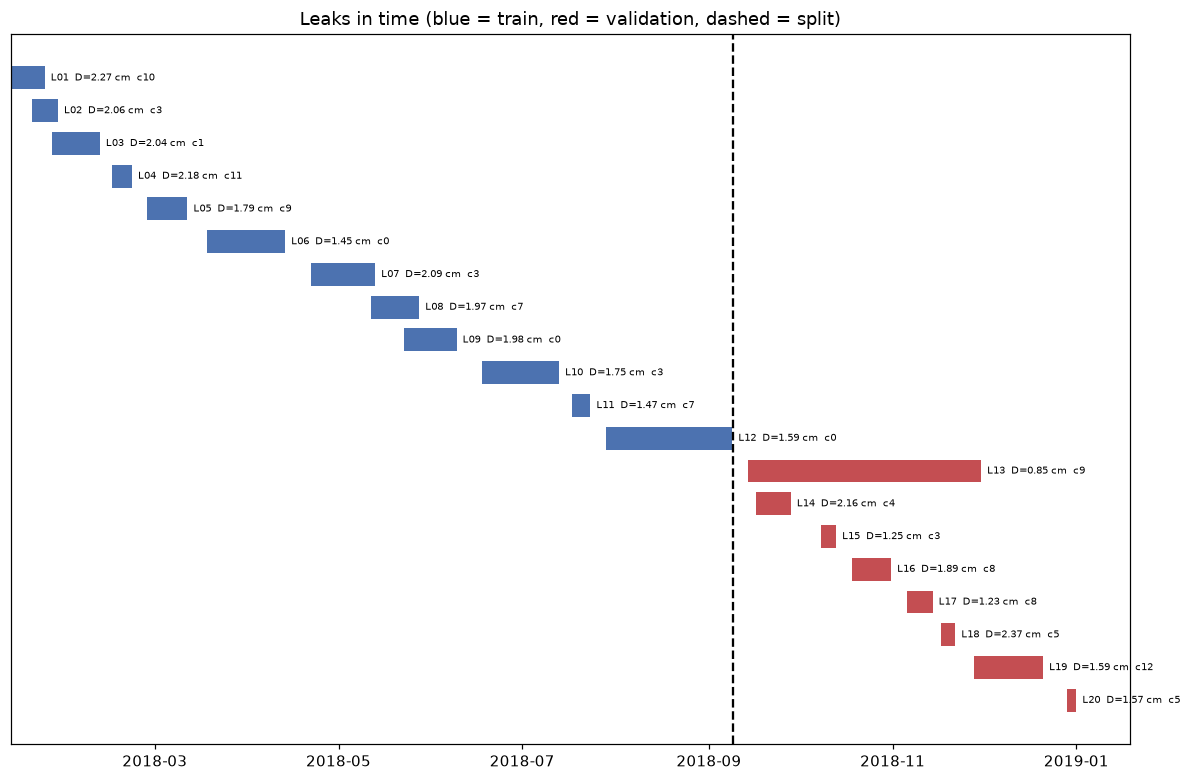

/tmp/ipykernel_103596/1181960825.py:28: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(lk[lk['split'] == 'validation'][['leak_id', 'pipe_id', 'type', 'diameter_m', 'start', 'end', 'cluster', 'z_over_noise']].round(2))


,leak_id,pipe_id,type,diameter_m,start,end,cluster,z_over_noise
12,L13,p678,incipient,0.01,2018-09-14 03:10:00,2018-11-30 09:00:00,9,1.12
13,L14,p281,abrupt,0.02,2018-09-16 13:20:00,2018-09-28 04:45:00,4,8.98
14,L15,p366,abrupt,0.01,2018-10-08 02:35:00,2018-10-13 05:35:00,3,1.19
15,L16,p707,abrupt,0.02,2018-10-18 11:00:00,2018-10-31 11:50:00,8,3.16
16,L17,p695,abrupt,0.01,2018-11-05 19:55:00,2018-11-14 06:50:00,8,1.15
17,L18,p591,abrupt,0.02,2018-11-17 03:50:00,2018-11-21 19:20:00,5,4.85
18,L19,p423,incipient,0.02,2018-11-27 23:10:00,2018-12-20 23:05:00,12,2.37
19,L20,p132,abrupt,0.02,2018-12-28 17:50:00,2018-12-31 23:55:00,5,2.03


In [16]:
lab = pd.read_csv(ROOT / 'historical_2018' / 'labels.csv', index_col=0, parse_dates=True)
idx, y = lab.index, lab['leak_active'].values
va = np.asarray(idx >= TRAIN_END)
THR = json.load(open(ART / 'cluster_info.json'))['noise_thr_95']
lk = pd.read_csv(ART / 'leaks_with_clusters.csv', parse_dates=['start', 'peak', 'end'])
lk['split'] = np.where(lk['start'] < TRAIN_END, 'train', 'validation')
lk['z_over_noise'] = lk['z_at_D'] / THR

print(f'train steps {int((~va).sum())} ({(~va).sum() / 288:.0f} days), leak share {y[~va].mean():.1%} | '
      f'validation steps {int(va.sum())} ({va.sum() / 288:.0f} days), leak share {y[va].mean():.1%}')
print('leaks: train', int((lk['split'] == 'train').sum()), '| validation', int((lk['split'] == 'validation').sum()))
if int((lk['split'] == 'validation').sum()) != N_VAL:
    warnings.warn(f"leaks.csv has {int((lk['split'] == 'validation').sum())} validation leaks but the result files say {N_VAL}: check TRAIN_END")

straddle = lk[(lk['start'] < TRAIN_END) & (lk['end'] > TRAIN_END)]
print('leaks that start before TRAIN_END and are still running after it (their later hours are validation rows):',
      list(straddle['leak_id']) or 'none')

fig, ax = plt.subplots(figsize=(11, 0.28 * len(lk) + 1.6))
for i, r in lk.sort_values('start').reset_index(drop=True).iterrows():
    ax.barh(i, (r['end'] - r['start']).total_seconds() / 86400, left=mdates.date2num(r['start']), height=.7,
            color='#4C72B0' if r['split'] == 'train' else '#C44E52')
    ax.text(mdates.date2num(r['end']) + 2, i, f"{r['leak_id']}  D={r['diameter_m'] * 100:.2f} cm  c{int(r['cluster'])}", va='center', fontsize=6.5)
ax.axvline(mdates.date2num(TRAIN_END), color='k', ls='--'); ax.xaxis_date(); ax.invert_yaxis(); ax.set_yticks([])
ax.set_title('Leaks in time (blue = train, red = validation, dashed = split)'); ax.grid(False)
plt.tight_layout(); savefig('p2_split_timeline'); plt.show()

display(lk[lk['split'] == 'validation'][['leak_id', 'pipe_id', 'type', 'diameter_m', 'start', 'end', 'cluster', 'z_over_noise']].round(2))

<div dir="rtl" style="text-align:right">

**چطور بخوانیم:** (۱) نشتی که پیش از `TRAIN_END` شروع و بعد از آن ادامه دارد، ساعت‌های اولش در آموزش و ساعت‌های بعدی‌اش در سطرهای اعتبارسنجی است؛ این نشت جزو رخدادهای اعتبارسنجی حساب نمی‌شود ولی نشت جزئی داده است و باید در گزارش ذکر شود. (۲) ستون `z_over_noise` برای نشت‌های اعتبارسنجی نشان می‌دهد کدام‌ها در اندازه خودشان هم به‌سختی بالاتر از نویزند (کمتر از حدود ۱ یعنی تقریباً نامرئی)؛ سقف واقع‌بینانه «تعداد نشت تشخیص‌داده‌شده» از `{تعداد اعتبارسنجی}` کمتر است. (۳) سهم گام‌های نشت‌دار در آموزش و اعتبارسنجی توجیه‌کننده وزن‌دهی کلاس‌هاست.

</div>

<div dir="rtl" style="text-align:right">

## ۳. نمای کلی طرح‌های آشکارساز

جدول همه طرح‌ها و نمودار مصالحه «تعداد نشت‌های تشخیص‌داده‌شده در برابر هشدار کاذب». طرح‌های روی مرز پارتو (نه بیشتر تشخیص و نه کمتر هشدار کاذب و AUROC بدتر) مشخص شده‌اند.

</div>

,id,input,train_data,AUROC,AUROC_visible,detected,delay_h,FA_per30,rule,params,n_in,n_train,train_s,pareto
0,B1,نرم باقیمانده سفیدشده ۶ ساعته + آستانه,بدون آموزش (فقط خط پایه و کوواریانس نویز),0.906,0.985,8/8,2.042,0.000,p>=0.5 for 36 steps,NaN,NaN,NaN,NaN,True
1,W3,انحراف از خط پایه (فقط فشار)؛ پنجره 3 ساعته,واقعی + ۳۰۰ نشت مصنوعی,0.918,0.983,8/8,2.250,0.000,p>=0.7 for 36 steps,13057.0,36.0,52689.0,15.359,False
2,N3b,انحراف از خط پایه؛ ۱/۳/۶ ساعته + سفیدسازی + ویژگی نرم,واقعی + ۳۰۰ نشت مصنوعی,0.906,0.982,8/8,1.000,0.000,p>=0.8 for 12 steps,21889.0,105.0,52689.0,30.073,False
3,N2d,انحراف از خط پایه (فقط فشار، بدون سفیدسازی)؛ ۱/۶/۲۴,واقعی + ۳۰۰ نشت مصنوعی,0.873,0.981,8/8,12.167,0.000,p>=0.3 for 144 steps,21505.0,102.0,52689.0,42.510,False
4,Wmulti,انحراف از خط پایه (فقط فشار)؛ پنجره‌های ۱/۶/۲۴ ساعته,واقعی + ۳۰۰ نشت مصنوعی,0.873,0.981,8/8,12.167,0.000,p>=0.3 for 144 steps,21505.0,102.0,52689.0,17.907,False
5,W1,انحراف از خط پایه (فقط فشار)؛ پنجره 1 ساعته,واقعی + ۳۰۰ نشت مصنوعی,0.899,0.975,8/8,1.250,0.000,p>=0.8 for 12 steps,13057.0,36.0,52689.0,6.017,False
6,N3a,انحراف از خط پایه (فقط فشار)؛ ۱/۳/۶ ساعته,واقعی + ۳۰۰ نشت مصنوعی,0.910,0.975,8/8,3.042,0.000,p>=0.3 for 36 steps,21505.0,102.0,52689.0,49.172,False
7,W12,انحراف از خط پایه (فقط فشار)؛ پنجره 12 ساعته,واقعی + ۳۰۰ نشت مصنوعی,0.903,0.974,8/8,13.583,0.000,p>=0.3 for 144 steps,13057.0,36.0,52689.0,13.708,False
8,N3c,انحراف از خط پایه؛ پنجره ۳ ساعته؛ سه لایه پنهان (128/64/32),واقعی + ۳۰۰ نشت مصنوعی,0.900,0.970,8/8,1.750,0.000,p>=0.95 for 12 steps,15105.0,36.0,52689.0,44.504,False
9,N2a,فشار خام؛ ۱/۶/۲۴ ساعته,واقعی + ۳۰۰ نشت مصنوعی,0.843,0.966,8/8,1.042,0.000,p>=0.95 for 1 steps,21505.0,102.0,52689.0,31.443,False


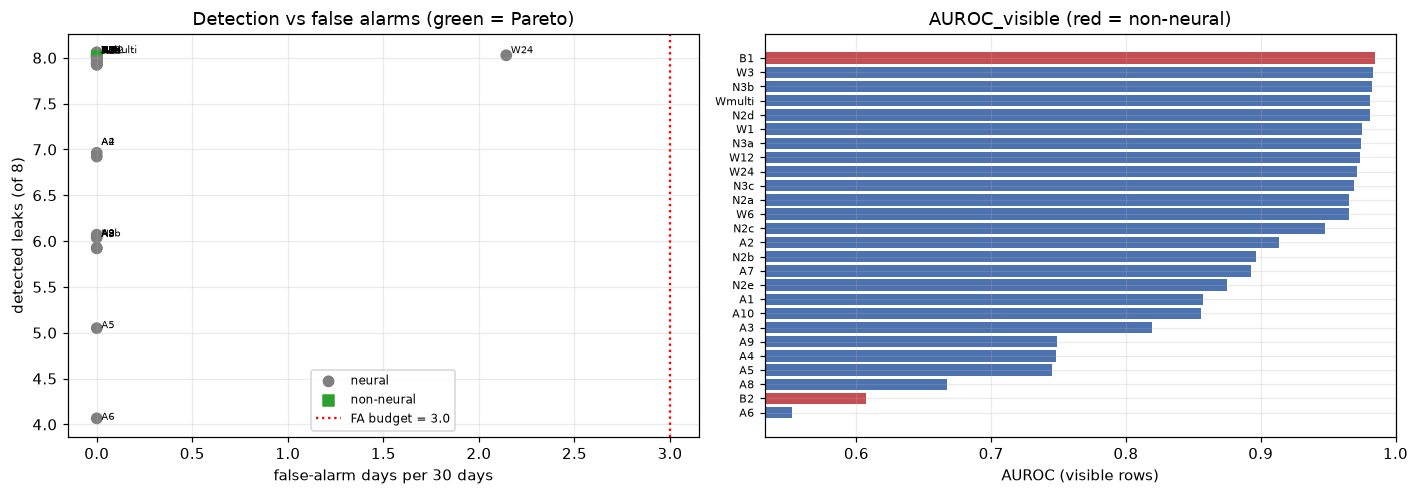

In [4]:
def pareto(df, maximize, minimize):
    pts = np.column_stack([df[c].fillna(df[c].min() if c in maximize else df[c].max()).values.astype(float) for c in maximize] +
                          [-df[c].fillna(df[c].max()).values.astype(float) for c in minimize])
    ok = np.ones(len(df), bool)
    for i in range(len(df)):
        ok[i] = not ((pts >= pts[i]).all(1) & (pts > pts[i]).any(1)).any()
    return ok


det['pareto'] = pareto(det, ['n_det', 'AUROC_visible'], ['FA_per30'])
cols = ['id', 'input', 'train_data', 'AUROC', 'AUROC_visible', 'detected', 'delay_h', 'FA_per30', 'rule', 'params', 'n_in', 'n_train', 'train_s', 'pareto']
view = det.sort_values(['n_det', 'FA_per30', 'AUROC_visible'], ascending=[False, True, False])
display(view[cols].round(3).reset_index(drop=True))
view[cols].to_csv(ART / 'part2_detector_summary.csv', index=False, encoding='utf-8-sig')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for kind, mk in (('neural', 'o'), ('non-neural', 's')):
    d = det[det['kind'] == kind]
    ax[0].scatter(d['FA_per30'], d['n_det'] + np.random.default_rng(0).uniform(-.08, .08, len(d)), marker=mk, s=45,
                  c=np.where(d['pareto'], 'tab:green', 'tab:gray'), label=kind)
    for _, r in d.iterrows():
        ax[0].annotate(r['id'], (r['FA_per30'], r['n_det']), fontsize=6.5, xytext=(3, 3), textcoords='offset points')
ax[0].axvline(FA_BUDGET, color='r', ls=':', label=f'FA budget = {FA_BUDGET}')
ax[0].set_xlabel('false-alarm days per 30 days'); ax[0].set_ylabel(f'detected leaks (of {N_VAL})'); ax[0].legend(fontsize=8)
ax[0].set_title('Detection vs false alarms (green = Pareto)')
o = det.sort_values('AUROC_visible')
ax[1].barh(o['id'], o['AUROC_visible'], color=np.where(o['kind'] == 'non-neural', '#C44E52', '#4C72B0'))
ax[1].set_xlim(max(0.5, o['AUROC_visible'].min() - 0.02), 1.0); ax[1].set_xlabel('AUROC (visible rows)'); ax[1].tick_params(axis='y', labelsize=7)
ax[1].set_title('AUROC_visible (red = non-neural)')
plt.tight_layout(); savefig('p2_detector_overview'); plt.show()

<div dir="rtl" style="text-align:right">

## ۴. کف نویز آموزش

همه طرح‌ها فقط با `seed=0` آموزش دیده‌اند. یک MLP با شروع تصادفی دیگر می‌تواند چند صدم AUROC و یک یا دو نشت تفاوت بدهد، پس تفاوت دو طرح تنها وقتی معنی دارد که از **کف نویز** بزرگ‌تر باشد. اگر اجرای چند-seed در `artifacts/part2_detector_seeds.csv` باشد، کف نویز از آن می‌آید (برای تفاوت دو اجرا، $2\sqrt{2}\,\bar\sigma$ تقریباً باند ۹۵٪ است)؛ وگرنه از `DEFAULT_NOISE`.

برای تولید این فایل برای ۳ تا ۴ طرح نهایی، این شاخه را به `run_part2_detector.py` اضافه کنید (۵ seed کافی است):

```python
if which == 'S':
    res = []
    for nm, cfg, sy in [('N3b', dict(mode='resid', channels='P', windows=[1, 3, 6], whiten=True, norms=True, **C), 300),
                        ('Wmulti', dict(BEST), 300),
                        ('A5', dict(mode='resid', channels='PF', windows=[1, 6, 24], whiten=True, **C), 0)]:
        for seed in range(5):
            rec, _ = mlp_design(f'{nm} seed={seed}', cfg, synth=sy, seed=seed)
            rec['design'], rec['seed'] = nm, seed
            res.append(rec)
    pd.DataFrame(res).to_csv(pl.ART + '/part2_detector_seeds.csv', index=False)
```

</div>

In [5]:
M = ['AUROC_visible', 'n_det', 'delay_h', 'FA_per30']
sf = ART / 'part2_detector_seeds.csv'
if sf.exists():
    seeds = pd.read_csv(sf)
    seeds['id'] = seeds['design'].map(design_id)
    seeds['n_det'] = seeds['detected'].astype(str).str.split('/').str[0].astype(int)
    display(seeds.groupby('id')[M].agg(['mean', 'std']).round(3))
    sd = seeds.groupby('id')[M].std().median()
    NOISE = {m: float(2 * np.sqrt(2) * sd[m]) for m in M}
    NOISE['n_det'] = float(max(1, round(NOISE['n_det'])))
    NOISE_SRC = f'multi-seed ({seeds["seed"].nunique()} seeds)'
else:
    NOISE, NOISE_SRC = dict(DEFAULT_NOISE), 'DEFAULT_NOISE (no multi-seed run found)'
    print('no part2_detector_seeds.csv: differences below the default tolerance are treated as ties, but this is an assumption.')
print('noise floor from', NOISE_SRC, '->', {k: round(v, 3) for k, v in NOISE.items()})

no part2_detector_seeds.csv: differences below the default tolerance are treated as ties, but this is an assumption.
noise floor from DEFAULT_NOISE (no multi-seed run found) -> {'AUROC_visible': 0.01, 'n_det': 1, 'delay_h': 1.0, 'FA_per30': 0.5}


<div dir="rtl" style="text-align:right">

## ۵. مقایسه‌های کنترل‌شده (ablation)

هر ردیف یک سؤال با دقیقاً یک تغییر است (طرح مبنا ← طرح تغییریافته). نوار خاکستری باند کف نویز است؛ تغییری که در آن باند بماند را «بی‌اثر قابل تشخیص» بنویسید. رنگ سبز یعنی بهبود و قرمز یعنی بدتر شدن، با توجه به جهت هر معیار (AUROC و تعداد تشخیص بیشتر بهتر؛ تأخیر و هشدار کاذب کمتر بهتر است).

</div>

,question,base,variant,d_AUROC_visible,d_n_det,d_delay_h,d_FA_per30
0,raw -> baseline residual,A2,A3,-0.094,-1,67.833,0.0
1,raw -> residual (with synthetic),N2a,N2d,0.015,0,11.125,0.0
2,+ noise whitening,A3,A4,-0.071,1,-71.417,0.0
3,+ flows & tank (whitened resid),A4,A5,-0.003,-2,3.167,0.0
4,"+ flows & tank (resid, synthetic)",N2d,N2e,-0.106,0,0.000,0.0
5,"+ flows & tank (raw, real)",A2,N2b,-0.017,-1,12.792,0.0
6,"+ flows & tank (raw, synthetic)",N2a,N2c,-0.018,0,15.917,0.0
7,baseline WITHOUT AMR,A5,A6,-0.193,-1,-0.542,0.0
8,+ synthetic leaks (A5),A5,A7,0.148,3,1.250,0.0
9,+ synthetic leaks (with norms),A9,A10,0.107,2,2.333,0.0


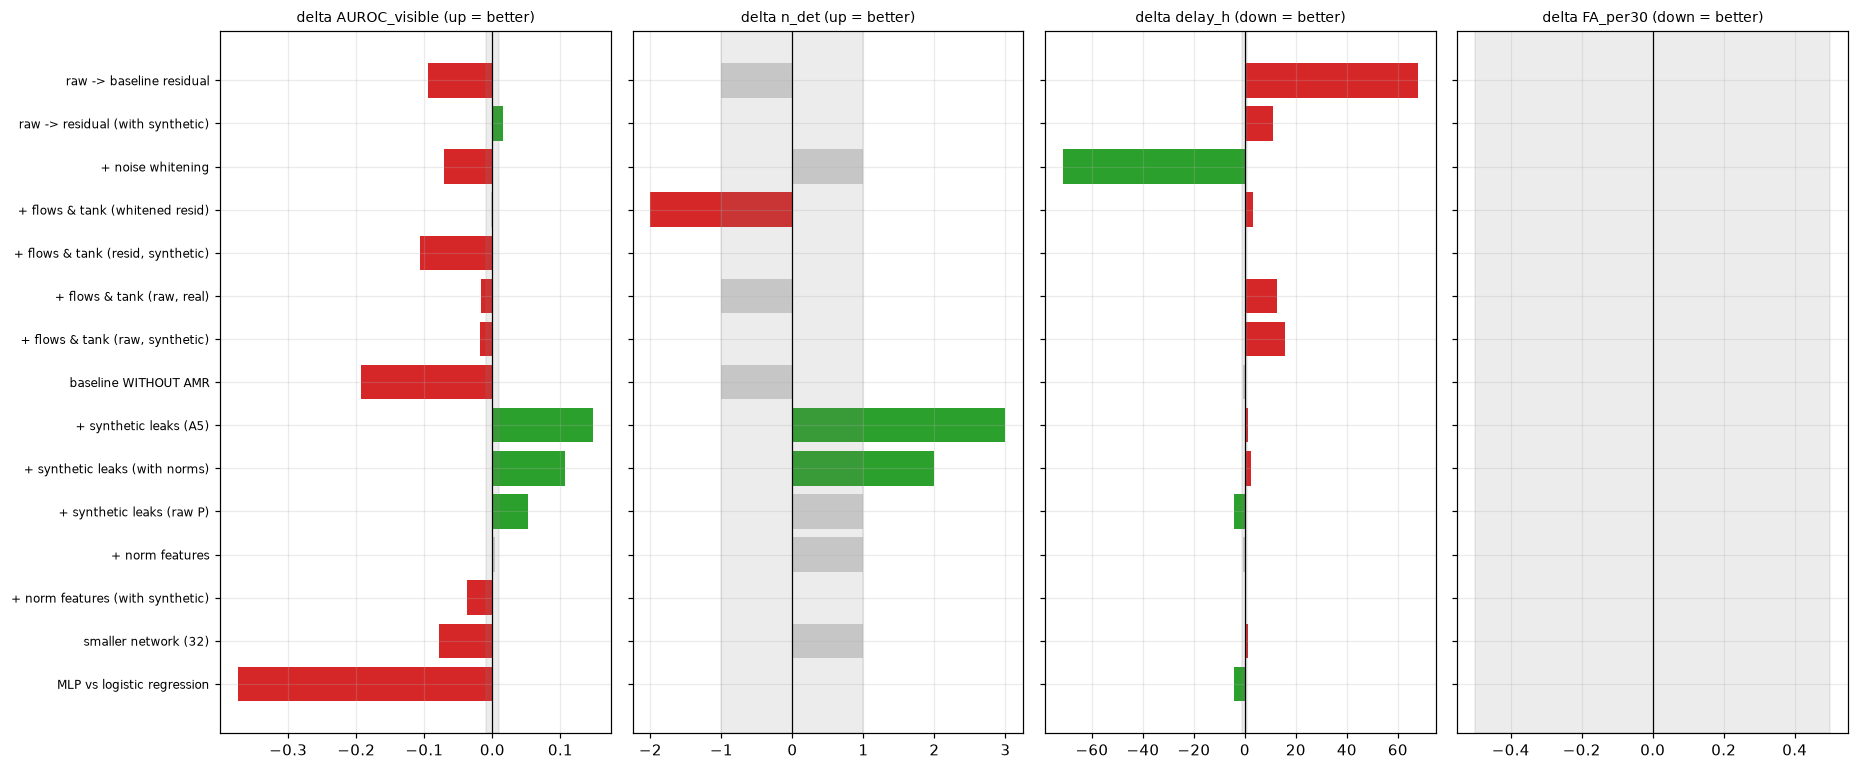

In [6]:
PAIRS = [  # (english label for the plot, question in Persian, base id, variant id)
    ('raw -> baseline residual', 'خام ← انحراف از خط پایه', 'A2', 'A3'),
    ('raw -> residual (with synthetic)', 'خام ← انحراف از خط پایه (با مصنوعی)', 'N2a', 'N2d'),
    ('+ noise whitening', 'افزودن سفیدسازی نویز', 'A3', 'A4'),
    ('+ flows & tank (whitened resid)', 'افزودن جریان و تراز (باقیمانده سفیدشده)', 'A4', 'A5'),
    ('+ flows & tank (resid, synthetic)', 'افزودن جریان و تراز (باقیمانده، با مصنوعی)', 'N2d', 'N2e'),
    ('+ flows & tank (raw, real)', 'افزودن جریان و تراز (خام، واقعی)', 'A2', 'N2b'),
    ('+ flows & tank (raw, synthetic)', 'افزودن جریان و تراز (خام، با مصنوعی)', 'N2a', 'N2c'),
    ('baseline WITHOUT AMR', 'حذف AMR از خط پایه', 'A5', 'A6'),
    ('+ synthetic leaks (A5)', 'افزودن نشت مصنوعی (A5)', 'A5', 'A7'),
    ('+ synthetic leaks (with norms)', 'افزودن نشت مصنوعی (با ویژگی نرم)', 'A9', 'A10'),
    ('+ synthetic leaks (raw P)', 'افزودن نشت مصنوعی (فشار خام)', 'A2', 'N2a'),
    ('+ norm features', 'افزودن ویژگی نرم', 'A5', 'A9'),
    ('+ norm features (with synthetic)', 'افزودن ویژگی نرم (با مصنوعی)', 'A7', 'A10'),
    ('smaller network (32)', 'شبکه کوچک‌تر', 'A5', 'A8'),
    ('MLP vs logistic regression', 'MLP در برابر رگرسیون لجستیک (همان ورودی و داده)', 'Wmulti', 'B2'),
]
D = det.set_index('id')
rows = []
for en, fa, a, b in PAIRS:
    if a in D.index and b in D.index:
        rows.append(dict(question=en, question_fa=fa, base=a, variant=b, **{f'd_{m}': D.loc[b, m] - D.loc[a, m] for m in M}))
    else:
        print(f'skipped pair {a} -> {b} (missing result)')
abl = pd.DataFrame(rows)
display(abl.drop(columns='question_fa').round(3))
abl.to_csv(ART / 'part2_ablation_pairs.csv', index=False, encoding='utf-8-sig')

better_if_up = {'AUROC_visible': True, 'n_det': True, 'delay_h': False, 'FA_per30': False}
fig, ax = plt.subplots(1, 4, figsize=(17, 0.34 * len(abl) + 2), sharey=True)
for a_, m in zip(ax, M):
    d = abl[f'd_{m}'].fillna(0).values
    good = (d > 0) if better_if_up[m] else (d < 0)
    col = np.where(np.abs(d) <= NOISE[m], 'lightgray', np.where(good, 'tab:green', 'tab:red'))
    a_.barh(range(len(abl)), d, color=col); a_.axvspan(-NOISE[m], NOISE[m], color='gray', alpha=.15)
    a_.axvline(0, color='k', lw=.8); a_.set_title('delta ' + m + (' (up = better)' if better_if_up[m] else ' (down = better)'), fontsize=9)
ax[0].set_yticks(range(len(abl))); ax[0].set_yticklabels(abl['question'], fontsize=8); ax[0].invert_yaxis()
plt.tight_layout(); savefig('p2_ablations'); plt.show()

<div dir="rtl" style="text-align:right">

**چطور بخوانیم و چه بنویسیم:**

- **خط پایه:** اگر انحراف از خط پایه (A3 و N2d) نسبت به فشار خام (A2 و N2a) بهتر است، دلیلش این است که فشار مطلق تحت تأثیر تقاضای روزانه و فصل است و خط پایه آن را حذف می‌کند. اگر تفاوتی نبود، شبکه خودش خط پایه را از ساعت روز آموخته است.
- **سفیدسازی:** اگر اثر آن در باند نویز است، نمی‌توانید بگویید لازم است؛ ولی هزینه‌ای هم ندارد و برای مکان‌یاب مهم‌تر است (بخش ۹).
- **جریان و تراز:** هر چهار زوج را با هم بخوانید. اگر فقط در حالت «خام» کمک می‌کند، یعنی چیزی را جبران می‌کند که خط پایه هم می‌دهد.
- **AMR:** در این طرح‌ها AMR فقط در خط پایه است و جدا از جریان‌ها و تراز آزموده نشده؛ ادعای شما فقط درباره «حذف AMR از خط پایه» است.
- **داده مصنوعی:** این زوج‌ها سؤال «آیا امضای مدل به واقعیت منتقل می‌شود» را به‌طور غیرمستقیم می‌سنجند؛ آزمون مستقیم در بخش ۴ پروژه (آموزش صرفاً مصنوعی) است.
- **MLP در برابر LR:** این تنها مقایسه‌ای است که ورودی و داده یکسان دارد (`Wmulti` و `B2`)؛ اگر تفاوت کوچک است، ادعای «MLP لازم است» را نکنید.

</div>

<div dir="rtl" style="text-align:right">

## ۶. طول پنجره: ۱ تا ۲۴ ساعت

پنجره‌های ۱، ۳، ۶، ۱۲ و ۲۴ ساعته (باقیمانده فشار + داده مصنوعی) و ترکیب ۱/۶/۲۴. انتظار مصالحه این است: پنجره کوتاه واکنش سریع ولی نویزی، پنجره بلند نویز کمتر ولی تأخیر بیشتر.

</div>

,id,w,AUROC,AUROC_visible,detected,delay_h,FA_per30,rule,n_in,params
0,W1,1,0.899,0.975,8/8,1.250,0.000,p>=0.8 for 12 steps,36.0,13057.0
1,W3,3,0.918,0.983,8/8,2.250,0.000,p>=0.7 for 36 steps,36.0,13057.0
2,W6,6,0.891,0.965,8/8,7.167,0.000,p>=0.9 for 72 steps,36.0,13057.0
3,W12,12,0.903,0.974,8/8,13.583,0.000,p>=0.3 for 144 steps,36.0,13057.0
4,W24,24,0.873,0.972,8/8,4.667,2.143,p>=0.3 for 72 steps,36.0,13057.0


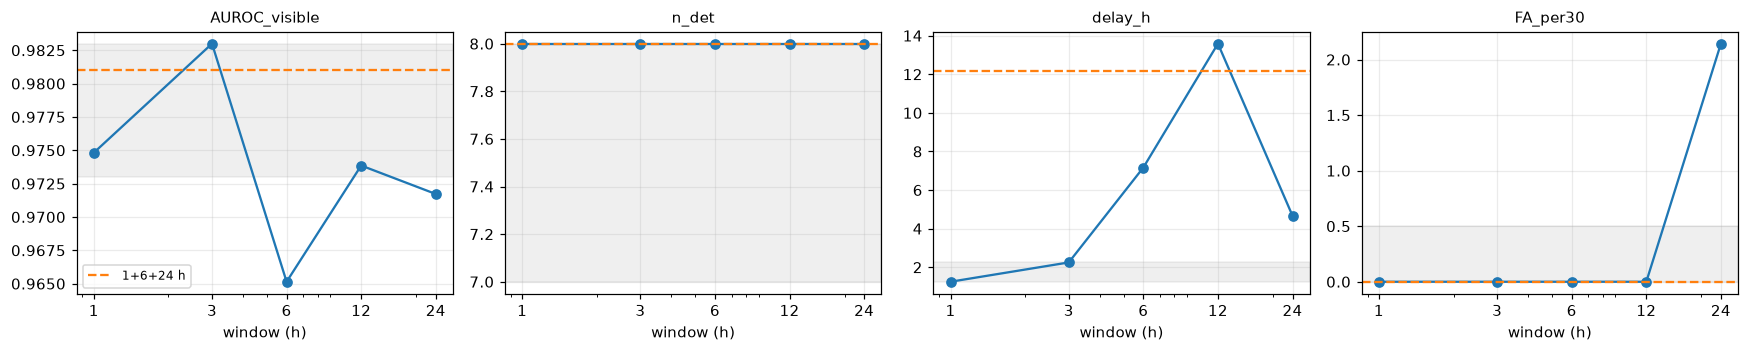

In [7]:
wd = det[det['id'].str.match(r'^W\d+$')].copy()
if wd.empty:
    print('window results not found: run  python run_part2_detector.py W')
else:
    wd['w'] = wd['id'].str[1:].astype(int); wd = wd.sort_values('w')
    display(wd[['id', 'w', 'AUROC', 'AUROC_visible', 'detected', 'delay_h', 'FA_per30', 'rule', 'n_in', 'params']].round(3).reset_index(drop=True))
    fig, ax = plt.subplots(1, 4, figsize=(16, 3.3))
    for a_, m in zip(ax, M):
        a_.plot(wd['w'], wd[m], 'o-'); a_.set_xscale('log'); a_.set_xticks(wd['w']); a_.set_xticklabels(wd['w'])
        if 'Wmulti' in D.index:
            a_.axhline(D.loc['Wmulti', m], color='tab:orange', ls='--', label='1+6+24 h')
        a_.axhspan(wd[m].max() - NOISE[m], wd[m].max(), color='gray', alpha=.12) if better_if_up[m] else a_.axhspan(wd[m].min(), wd[m].min() + NOISE[m], color='gray', alpha=.12)
        a_.set_xlabel('window (h)'); a_.set_title(m, fontsize=10)
    ax[0].legend(fontsize=8); plt.tight_layout(); savefig('p2_window_length'); plt.show()

<div dir="rtl" style="text-align:right">

**چطور بخوانیم:** نوار خاکستری ناحیه «به اندازه بهترین، در حد نویز» است. اگر چند پنجره در آن می‌افتند، **کوتاه‌ترین** آن‌ها را برگزینید (تأخیر کمتر، ورودی کوچک‌تر). اگر پنجره ۲۴ ساعته تنها برای نشت‌های تدریجی بهتر است، مصالحه را با گزارش تأخیر هر نشت بنویسید. ترکیب چندپنجره‌ای اگر از بهترین پنجره تکی بهتر نیست، ورودی بزرگ‌تر ارزشی نداشته است. توجه: همه طرح‌های این بخش بدون سفیدسازی‌اند (`BEST` اسکریپت)؛ اگر طرح نهایی شما سفیدسازی دارد، کوتاه‌ترین پنجره را برای همان طرح دوباره بیازمایید.

</div>

<div dir="rtl" style="text-align:right">

## ۷. مبناهای غیرعصبی

`B1` فقط نرم باقیمانده سفیدشده را آستانه‌گذاری می‌کند (هیچ یادگیری‌ای جز خط پایه و کوواریانس نویز ندارد) و `B2` رگرسیون لجستیک روی همان ورودی و همان داده آموزش MLP است. هدف این است که نشان دهید MLP چه چیزی اضافه می‌کند.

</div>

In [8]:
ref_ids = [i for i in ['B1', 'B2', 'Wmulti'] if i in D.index]
best_nn = det[det['kind'] == 'neural'].sort_values(['n_det', 'AUROC_visible'], ascending=False).iloc[0]['id']
tab_b = det[det['id'].isin(ref_ids + [best_nn])][['id', 'input', 'AUROC', 'AUROC_visible', 'detected', 'delay_h', 'FA_per30', 'rule', 'train_s', 'params']]
display(tab_b.round(3).reset_index(drop=True))
print('best neural design by (detected, AUROC_visible):', best_nn)

,id,input,AUROC,AUROC_visible,detected,delay_h,FA_per30,rule,train_s,params
0,B1,نرم باقیمانده سفیدشده ۶ ساعته + آستانه,0.906,0.985,8/8,2.042,0.0,p>=0.5 for 36 steps,NaN,NaN
1,B2,رگرسیون لجستیک؛ همان ورودی و داده Wmulti,0.589,0.607,8/8,8.000,0.0,p>=0.5 for 6 steps,4.071,NaN
2,W3,انحراف از خط پایه (فقط فشار)؛ پنجره 3 ساعته,0.918,0.983,8/8,2.250,0.0,p>=0.7 for 36 steps,15.359,13057.0
3,Wmulti,انحراف از خط پایه (فقط فشار)؛ پنجره‌های ۱/۶/۲۴ ساعته,0.873,0.981,8/8,12.167,0.0,p>=0.3 for 144 steps,17.907,21505.0


best neural design by (detected, AUROC_visible): W3


<div dir="rtl" style="text-align:right">

## ۸. انتخاب آشکارساز با قاعده از پیش تعیین‌شده

قاعده (ترتیب لغت‌نامه‌ای، بدون وزن‌دهی دلخواه):

1. فقط طرح‌های عصبی با `FA_per30 ≤ FA_BUDGET`؛
2. بیشترین تعداد نشت تشخیص‌داده‌شده؛ سپس بیشترین `AUROC_visible`؛ سپس کمترین میانه تأخیر؛
3. طرح‌هایی که در **همه** معیارها از بهترین فقط به اندازه کف نویز عقب‌اند «برابر» حساب می‌شوند و از میانشان **ساده‌ترین** (کمترین پارامتر، سپس کمترین ورودی) انتخاب می‌شود.

خروجی این بخش پیشنهاد است نه حکم: بخش ۳ گزارش باید دلیل نهایی و نتایجی را که تصمیم را عوض می‌کنند بنویسد.

</div>

In [9]:
cand = det[det['kind'] == 'neural'].copy()
ok = cand[cand['FA_per30'] <= FA_BUDGET]
if ok.empty:
    warnings.warn(f'no neural design satisfies FA <= {FA_BUDGET}; falling back to the lowest FA ones')
    ok = cand[cand['FA_per30'] <= cand['FA_per30'].min() + NOISE['FA_per30']]
ok = ok.sort_values(['n_det', 'AUROC_visible', 'delay_h', 'FA_per30'], ascending=[False, False, True, True])
top = ok.iloc[0]
tie = ok[(top['n_det'] - ok['n_det'] <= NOISE['n_det']) &
         (top['AUROC_visible'] - ok['AUROC_visible'] <= NOISE['AUROC_visible']) &
         (ok['delay_h'].fillna(1e9) - top['delay_h'] <= NOISE['delay_h'])]
tie = tie.assign(_p=tie['params'].fillna(np.inf), _n=tie['n_in'].fillna(np.inf)).sort_values(['_p', '_n'])
chosen_det = tie.iloc[0]
print(f'{len(ok)} designs satisfy FA <= {FA_BUDGET}; best by the lexicographic order: {top["id"]}; tied with it (within the noise floor): {list(tie["id"])}')
print('PROPOSED detector:', chosen_det['id'], '-', chosen_det['input'])
display(ok.head(6)[['id', 'input', 'AUROC_visible', 'detected', 'delay_h', 'FA_per30', 'params', 'n_in']].round(3))
if 'N3b' in D.index and chosen_det['id'] != 'N3b':
    print("NOTE: run_part2_localiser.py uses design N3b as its detector. If the proposal above differs, either justify N3b or re-run the localiser with the chosen design.")
if 'Wmulti' in D.index and chosen_det['id'] not in ('Wmulti',) and chosen_det['family'] != 'window':
    print('NOTE: the window study (section 6) used the BEST config, not the proposed design.')

24 designs satisfy FA <= 3.0; best by the lexicographic order: W3; tied with it (within the noise floor): ['W3', 'W1', 'N3a', 'N3b']
PROPOSED detector: W3 - انحراف از خط پایه (فقط فشار)؛ پنجره 3 ساعته


,id,input,AUROC_visible,detected,delay_h,FA_per30,params,n_in
21,W3,انحراف از خط پایه (فقط فشار)؛ پنجره 3 ساعته,0.983,8/8,2.250,0.0,13057.0,36.0
18,N3b,انحراف از خط پایه؛ ۱/۳/۶ ساعته + سفیدسازی + ویژگی نرم,0.982,8/8,1.000,0.0,21889.0,105.0
15,N2d,انحراف از خط پایه (فقط فشار، بدون سفیدسازی)؛ ۱/۶/۲۴,0.981,8/8,12.167,0.0,21505.0,102.0
25,Wmulti,انحراف از خط پایه (فقط فشار)؛ پنجره‌های ۱/۶/۲۴ ساعته,0.981,8/8,12.167,0.0,21505.0,102.0
20,W1,انحراف از خط پایه (فقط فشار)؛ پنجره 1 ساعته,0.975,8/8,1.250,0.0,13057.0,36.0
17,N3a,انحراف از خط پایه (فقط فشار)؛ ۱/۳/۶ ساعته,0.975,8/8,3.042,0.0,21505.0,102.0


NOTE: run_part2_localiser.py uses design N3b as its detector. If the proposal above differs, either justify N3b or re-run the localiser with the chosen design.


<div dir="rtl" style="text-align:right">

## ۹. مکان‌یاب

مکان‌یاب در گام‌هایی ارزیابی می‌شود که آشکارساز هشدار می‌دهد. به همین دلیل `top1` و `search_effort` با نشت‌های **تشخیص‌داده‌نشده** (top1 = ۰ و تلاش = ۱) آلوده می‌شوند. برای جدا کردن کیفیت خود مکان‌یاب از آشکارساز، مقدار «مشروط به تشخیص» هم حساب می‌شود:

$$\text{top1}_{|det} = \text{top1}\cdot\frac{N}{d},\qquad \text{effort}_{|det} = \frac{N\cdot\text{effort}-(N-d)}{d}$$

با $N$ تعداد نشت‌های اعتبارسنجی و $d$ تعداد نشت‌های تشخیص‌داده‌شده توسط **همان آشکارساز اسکریپت مکان‌یاب** (`N3b`). مقدار `d` را با خط چاپ‌شده `detector rule … detected d/N` در اجرای `run_part2_localiser.py` مطابقت دهید.

دو مرجع تصادفی: رتبه‌بندی تصادفی خوشه‌ها و رتبه‌بندی بر اساس اندازه خوشه (بزرگ‌ترین اول). مکان‌یابی که از این‌ها بهتر نباشد چیزی یاد نگرفته است.

</div>

detected leaks used for the conditional metrics: N_DET_LOC = 8 of 8
references (all leaks detected): random order  top1 0.07  effort 0.53 | size-prior  top1 0.00  effort 0.73


,id,input,train_data,top1,search_effort,top1_given_det,effort_given_det,n_train,n_in,params,train_s
0,L1,باقیمانده سفیدشده ۶ ساعته,واقعی (دوره آموزش),0.145,0.713,0.145,0.713,7033.0,36.0,13447.0,1.201
1,L2,بردار واحد + لگاریتم نرم باقیمانده ۶ ساعته,واقعی (دوره آموزش),0.196,0.703,0.196,0.703,7033.0,37.0,13575.0,1.059
2,L3,مثل L2,واقعی + ۶۰۰ قطعه مصنوعی,0.632,0.105,0.632,0.105,37310.0,37.0,14030.0,8.070
3,L4,باقیمانده سفیدشده ۶ و ۲۴ ساعته,واقعی + ۶۰۰ قطعه مصنوعی,0.589,0.112,0.589,0.112,37310.0,69.0,18126.0,14.699
4,L5,بردار واحد ۶ ساعته + پنجره ۲۴ ساعته,واقعی + ۶۰۰ قطعه مصنوعی,0.589,0.109,0.589,0.109,37310.0,70.0,18254.0,6.951
5,L6,مثل L3,فقط مصنوعی (۶۰۰ قطعه),0.485,0.117,0.485,0.117,30277.0,37.0,14030.0,9.060
6,L7,مثل L3 بدون سفیدسازی,واقعی + ۶۰۰ قطعه مصنوعی,0.509,0.132,0.509,0.132,37310.0,37.0,14030.0,8.114
7,B3,نزدیک‌ترین مرکز خوشه (کسینوس، سفیدشده),فقط مدل هیدرولیکی,0.350,0.263,0.350,0.263,NaN,NaN,NaN,NaN


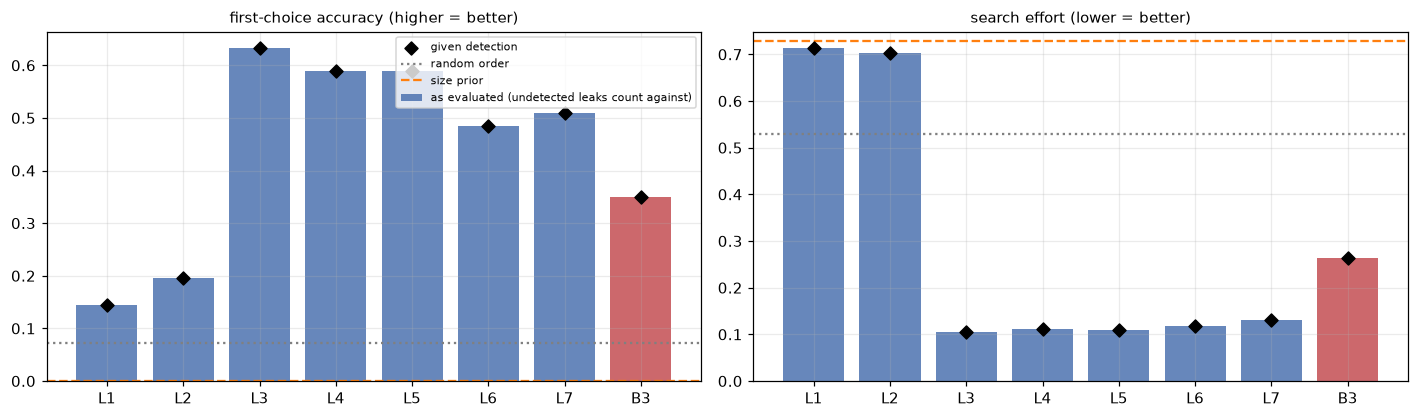

In [10]:
loc = pd.read_csv(ART / 'part2_localiser_designs.csv')
loc['id'] = loc['design'].map(design_id)
loc['input'] = loc['id'].map(lambda i: meta_of(i, 'input')); loc['train_data'] = loc['id'].map(lambda i: meta_of(i, 'train_data'))

d_row = det[det['id'] == 'N3b']
N_DET_LOC = int(d_row['n_det'].iloc[0]) if len(d_row) else None        # <- verify against run_part2_localiser.py output
print('detected leaks used for the conditional metrics: N_DET_LOC =', N_DET_LOC, f'of {N_VAL}')
if N_DET_LOC:
    loc['top1_given_det'] = loc['top1'] * N_VAL / N_DET_LOC
    loc['effort_given_det'] = (loc['search_effort'] * N_VAL - (N_VAL - N_DET_LOC)) / N_DET_LOC
    if (loc['effort_given_det'] < -1e-6).any():
        warnings.warn('negative conditional effort: N_DET_LOC does not match the detector used in run_part2_localiser.py')

cl = pd.read_csv(ROOT / 'clusters.csv')
K = cl['cluster'].nunique()
sizes = cl['cluster'].value_counts().sort_index().values.astype(float)
lk_val = lk[lk['split'] == 'validation']
c_val = lk_val['cluster'].astype(int).values
chance_top1 = 1 / K
chance_effort = float(np.mean([(sizes[c] + 0.5 * (sizes.sum() - sizes[c])) / sizes.sum() for c in c_val]))
rank_by_size = np.argsort(np.argsort(-sizes))                          # 0 = largest cluster
sizes_sorted = np.sort(sizes)[::-1]
prior_top1 = float(np.mean(rank_by_size[c_val] == 0))
prior_effort = float(np.mean([sizes_sorted[:rank_by_size[c] + 1].sum() / sizes.sum() for c in c_val]))
print(f'references (all leaks detected): random order  top1 {chance_top1:.2f}  effort {chance_effort:.2f} | '
      f'size-prior  top1 {prior_top1:.2f}  effort {prior_effort:.2f}')

show = ['id', 'input', 'train_data', 'top1', 'search_effort'] + (['top1_given_det', 'effort_given_det'] if N_DET_LOC else []) + ['n_train', 'n_in', 'params', 'train_s']
display(loc[show].round(3))
loc[show].to_csv(ART / 'part2_localiser_summary.csv', index=False, encoding='utf-8-sig')

fig, ax = plt.subplots(1, 2, figsize=(13, 3.9))
colors = ['#C44E52' if i.startswith('B') else '#4C72B0' for i in loc['id']]
for a_, col, cond, title, ref in ((ax[0], 'top1', 'top1_given_det', 'first-choice accuracy (higher = better)', (chance_top1, prior_top1)),
                                  (ax[1], 'search_effort', 'effort_given_det', 'search effort (lower = better)', (chance_effort, prior_effort))):
    a_.bar(loc['id'], loc[col], color=colors, alpha=.85, label='as evaluated (undetected leaks count against)')
    if N_DET_LOC: a_.scatter(loc['id'], loc[cond], marker='D', color='k', zorder=3, label='given detection')
    a_.axhline(ref[0], color='gray', ls=':', label='random order'); a_.axhline(ref[1], color='tab:orange', ls='--', label='size prior')
    a_.set_title(title, fontsize=10)
ax[0].legend(fontsize=7)
plt.tight_layout(); savefig('p2_localiser'); plt.show()

,leak_id,pipe_id,type,diameter_m,cluster,cluster_seen_in_real_train
12,L13,p678,incipient,0.00850,9,True
13,L14,p281,abrupt,0.02156,4,False
14,L15,p366,abrupt,0.01250,3,True
15,L16,p707,abrupt,0.01890,8,False
16,L17,p695,abrupt,0.01232,8,False
17,L18,p591,abrupt,0.02365,5,False
18,L19,p423,incipient,0.01587,12,False
19,L20,p132,abrupt,0.01575,5,False


75% of validation leaks lie in a cluster with NO real training leak -> a localiser trained on real leaks only cannot rank those clusters first (upper bound on top1 for real-only designs: 0.25 before the detector)


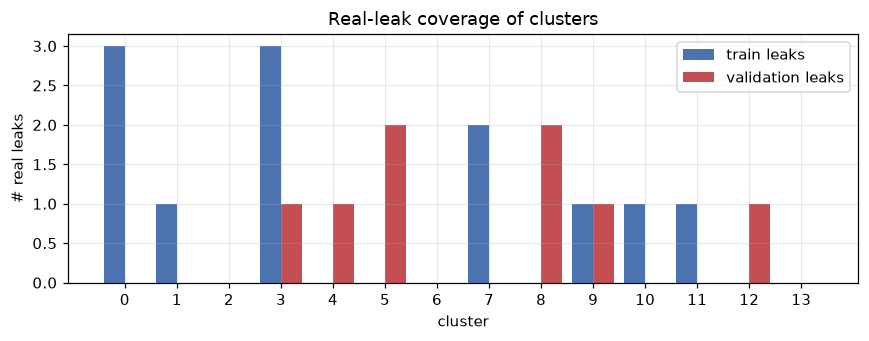

In [11]:
# ---- structural coverage: which validation clusters had ANY real training leak?
train_cl = set(lk.loc[lk['split'] == 'train', 'cluster'].astype(int))
lv = lk_val.assign(cluster=lk_val['cluster'].astype(int))
lv['cluster_seen_in_real_train'] = lv['cluster'].isin(train_cl)
display(lv[['leak_id', 'pipe_id', 'type', 'diameter_m', 'cluster', 'cluster_seen_in_real_train']])
unseen = float((~lv['cluster_seen_in_real_train']).mean())
print(f'{unseen:.0%} of validation leaks lie in a cluster with NO real training leak -> a localiser trained on real leaks only '
      f'cannot rank those clusters first (upper bound on top1 for real-only designs: {1 - unseen:.2f} before the detector)')

fig, ax = plt.subplots(figsize=(8, 3.2))
tr_cnt = lk[lk['split'] == 'train']['cluster'].astype(int).value_counts().reindex(range(K), fill_value=0)
va_cnt = lk_val['cluster'].astype(int).value_counts().reindex(range(K), fill_value=0)
ax.bar(np.arange(K) - .2, tr_cnt.values, width=.4, label='train leaks', color='#4C72B0')
ax.bar(np.arange(K) + .2, va_cnt.values, width=.4, label='validation leaks', color='#C44E52')
ax.set_xlabel('cluster'); ax.set_ylabel('# real leaks'); ax.set_xticks(range(K)); ax.legend(); ax.set_title('Real-leak coverage of clusters')
plt.tight_layout(); savefig('p2_cluster_coverage'); plt.show()

<div dir="rtl" style="text-align:right">

**چطور بخوانیم:**

- **مقایسه با مرجع‌ها:** مکان‌یابی که از «رتبه‌بندی بر اساس اندازه خوشه» بهتر نباشد، فقط پیشین کلاس‌ها را آموخته است.
- **با و بدون مصنوعی (`L2` ← `L3` ← `L6`):** `L6` فقط با داده مصنوعی آموزش دیده و روی نشت واقعی سنجیده می‌شود؛ این **آزمون مستقیم** فرض پرریسک (انتقال امضای مدل به واقعیت) برای مکان‌یاب است و باید در بخش ۴ دوباره بیاید. اگر `L6` به `L3` نزدیک است، مدل هیدرولیکی کافی است؛ اگر خیلی بدتر است، خطای مدل جدی است.
- **جدول پوشش:** وقتی نشت‌های اعتبارسنجی در خوشه‌هایی‌اند که نمونه واقعی آموزش ندارند، مکان‌یاب «فقط واقعی» ساختاراً نمی‌تواند رتبه اول بدهد؛ پس سنجش «واقعی در برابر مصنوعی» به این تفکیک وابسته است و باید در محدودیت‌ها بیاید.
- **سفیدسازی (`L7` ← `L3`) و بردار واحد (`L1` ← `L2`):** مکان‌یاب به شکل بردار حساس است و نه اندازه آن؛ اگر `L2/L3` از `L1` بهترند، این ادعا تأیید می‌شود.
- **با ۸ رخداد:** تفاوت `top1` به اندازه یک نشت برابر ۰٫۱۲۵ است. تفاوتی که از یک یا دو نشت کمتر باشد را قطعی نخوانید.
- **نشت‌های همپوشان در خوشه‌های متفاوت** (بخش ۷ نوت‌بوک ۰۲) سقف ساختاری دقت رتبه اول‌اند.

</div>

<div dir="rtl" style="text-align:right">

## ۱۰. ROC و بازه اطمینان (اختیاری، نیازمند ذخیره پیش‌بینی‌ها)

اسکریپت‌ها فقط جدول خلاصه می‌نویسند. برای منحنی ROC و بازه عدم قطعیت AUROC (که بخش ۵ پروژه برای «پیش‌بینی عملکرد با بازه» لازم دارد)، پیش‌بینی هر طرح را ذخیره کنید. در `mlp_design` بعد از محاسبه `p` این خط را اضافه کنید:

```python
slug = re.sub(r'\W+', '_', name).strip('_')
np.save(f"{pl.ART}/pred_det_{slug}.npy", p.astype('float32'))
```
و `import re` را به بالای اسکریپت اضافه کنید. بازه اطمینان با **bootstrap بلوکی** (بلوک‌های ۷ روزه) روی گام‌های اعتبارسنجی ساخته می‌شود تا همبستگی زمانی نادیده گرفته نشود. توجه: این بازه فقط عدم قطعیت نمونه‌برداری زمانی را نشان می‌دهد و نه تغییر seed و نه انتخاب طرح روی همین داده را.

</div>

In [12]:
slug = lambda s: re.sub(r'\W+', '_', s).strip('_')
have = {r['id']: ART / f"pred_det_{slug(r['design'])}.npy" for _, r in det.iterrows() if (ART / f"pred_det_{slug(r['design'])}.npy").exists()}
if not have:
    print('no saved predictions (artifacts/pred_det_*.npy): skipping ROC / bootstrap')
else:
    def block_bootstrap_auc(y_, p_, block=7 * 288, B=300, seed=0):
        rng, n = np.random.default_rng(seed), len(y_)
        nb = int(np.ceil(n / block)); out = []
        for _ in range(B):
            ii = np.concatenate([np.arange(s * block, min((s + 1) * block, n)) for s in rng.integers(0, nb, nb)])
            if y_[ii].min() != y_[ii].max():
                out.append(roc_auc_score(y_[ii], p_[ii]))
        return np.array(out)

    yv = y[va]; res = []
    fig, ax = plt.subplots(figsize=(5.4, 4.6))
    for i, f in have.items():
        p = np.load(f)[va]
        res.append(dict(id=i, AUROC=roc_auc_score(yv, p), **dict(zip(['ci_lo', 'ci_med', 'ci_hi'], np.quantile(block_bootstrap_auc(yv, p), [.025, .5, .975])))))
        fpr, tpr, _ = roc_curve(yv, p); ax.plot(fpr, tpr, label=f"{i} ({res[-1]['AUROC']:.3f})")
    ax.plot([0, 1], [0, 1], 'k:'); ax.set_xlabel('FPR'); ax.set_ylabel('TPR'); ax.legend(fontsize=7); ax.set_title('ROC on validation (all rows)')
    plt.tight_layout(); savefig('p2_roc'); plt.show()
    display(pd.DataFrame(res).round(3))

no saved predictions (artifacts/pred_det_*.npy): skipping ROC / bootstrap


<div dir="rtl" style="text-align:right">

## ۱۱. جدول گزارش بخش ۲

جدول تحویلی: روش، ورودی، داده آموزش، معیار انتخاب، نتایج، محدودیت‌ها. سطرهای پیش‌فرض: یک طرح از هر خانواده، مبناهای غیرعصبی و طرح پیشنهادی. `IDS_REPORT` را با نظر خودتان ویرایش کنید (گزارش دو صفحه‌ای جا برای همه ۲۵ طرح ندارد؛ جدول کامل در `artifacts/part2_detector_summary.csv` است).

</div>

In [13]:
IDS_REPORT = [i for i in ['A2', 'A3', 'A4', 'A5', 'A7', chosen_det['id'], 'Wmulti', 'B1', 'B2'] if i in D.index]
IDS_REPORT = list(dict.fromkeys(IDS_REPORT))
crit_det = f'تعداد نشت تشخیص‌داده‌شده، سپس هشدار کاذب ≤ {FA_BUDGET:g} روز/۳۰ روز، سپس AUROC و تأخیر؛ تفاوت کمتر از کف نویز = برابر'


def res_text(r):
    return f"AUROC_vis {r['AUROC_visible']:.3f}؛ تشخیص {r['detected']}؛ تأخیر {r['delay_h']:.1f} ساعت؛ FA {r['FA_per30']:.1f}/۳۰ روز"


def limit_text(r):
    return FAMILY_NOTE.get(r['family'], '') + '؛ یک seed و یک تفکیک زمانی'


rows = [{'روش': r['id'], 'ورودی': r['input'], 'داده آموزش': r['train_data'], 'معیار انتخاب': crit_det, 'نتایج': res_text(r), 'محدودیت‌ها': limit_text(r)}
        for _, r in det[det['id'].isin(IDS_REPORT)].set_index('id').loc[IDS_REPORT].reset_index().iterrows()]
rep_det = pd.DataFrame(rows)
rep_loc = pd.DataFrame([{'روش': r['id'], 'ورودی': r['input'], 'داده آموزش': r['train_data'],
                         'معیار انتخاب': 'دقت رتبه اول و تلاش جست‌وجو در گام‌های هشدار',
                         'نتایج': f"top1 {r['top1']:.2f}؛ تلاش {r['search_effort']:.2f}" +
                                  (f" (مشروط به تشخیص: {r['top1_given_det']:.2f} / {r['effort_given_det']:.2f})" if N_DET_LOC else ''),
                         'محدودیت‌ها': FAMILY_NOTE.get(meta_of(r['id'], 'family'), '') + f'؛ {N_VAL} رخداد اعتبارسنجی'}
                        for _, r in loc.iterrows()])
display(Markdown('**آشکارساز**')); display(rep_det)
display(Markdown('**مکان‌یاب**')); display(rep_loc)
rep_det.to_csv(ART / 'part2_report_table_detector.csv', index=False, encoding='utf-8-sig')
rep_loc.to_csv(ART / 'part2_report_table_localiser.csv', index=False, encoding='utf-8-sig')

**آشکارساز**

,روش,ورودی,داده آموزش,معیار انتخاب,نتایج,محدودیت‌ها
0,A2,فشار خام؛ میانگین‌های ۱/۶/۲۴ ساعته,واقعی (دوره آموزش),تعداد نشت تشخیص‌داده‌شده، سپس هشدار کاذب ≤ 3 روز/۳۰ روز، سپس AUROC...,AUROC_vis 0.914؛ تشخیص 7/8؛ تأخیر 5.2 ساعت؛ FA 0.0/۳۰ روز,نتیجه به انتخاب ورودی حساس است؛ فشار خام به فصل و الگوی تقاضا وابس...
1,A3,انحراف فشار از خط پایه آموخته‌شده؛ ۱/۶/۲۴ ساعته,واقعی (دوره آموزش),تعداد نشت تشخیص‌داده‌شده، سپس هشدار کاذب ≤ 3 روز/۳۰ روز، سپس AUROC...,AUROC_vis 0.819؛ تشخیص 6/8؛ تأخیر 73.0 ساعت؛ FA 0.0/۳۰ روز,نتیجه به انتخاب ورودی حساس است؛ فشار خام به فصل و الگوی تقاضا وابس...
2,A4,A3 + سفیدسازی نویز,واقعی (دوره آموزش),تعداد نشت تشخیص‌داده‌شده، سپس هشدار کاذب ≤ 3 روز/۳۰ روز، سپس AUROC...,AUROC_vis 0.748؛ تشخیص 7/8؛ تأخیر 1.6 ساعت؛ FA 0.0/۳۰ روز,نتیجه به انتخاب ورودی حساس است؛ فشار خام به فصل و الگوی تقاضا وابس...
3,A5,A4 + جریان‌ها و تراز مخزن,واقعی (دوره آموزش),تعداد نشت تشخیص‌داده‌شده، سپس هشدار کاذب ≤ 3 روز/۳۰ روز، سپس AUROC...,AUROC_vis 0.745؛ تشخیص 5/8؛ تأخیر 4.8 ساعت؛ FA 0.0/۳۰ روز,نتیجه به انتخاب ورودی حساس است؛ فشار خام به فصل و الگوی تقاضا وابس...
4,A7,A5,واقعی + ۳۰۰ نشت مصنوعی,تعداد نشت تشخیص‌داده‌شده، سپس هشدار کاذب ≤ 3 روز/۳۰ روز، سپس AUROC...,AUROC_vis 0.893؛ تشخیص 8/8؛ تأخیر 6.0 ساعت؛ FA 0.0/۳۰ روز,وابسته به شباهت امضای مدل به واقعیت (فرض پرریسک بخش ۴)؛ یک seed و ...
5,W3,انحراف از خط پایه (فقط فشار)؛ پنجره 3 ساعته,واقعی + ۳۰۰ نشت مصنوعی,تعداد نشت تشخیص‌داده‌شده، سپس هشدار کاذب ≤ 3 روز/۳۰ روز، سپس AUROC...,AUROC_vis 0.983؛ تشخیص 8/8؛ تأخیر 2.2 ساعت؛ FA 0.0/۳۰ روز,پنجره بلندتر تأخیر را زیاد می‌کند؛ تنها یک seed؛ یک seed و یک تفکی...
6,Wmulti,انحراف از خط پایه (فقط فشار)؛ پنجره‌های ۱/۶/۲۴ ساعته,واقعی + ۳۰۰ نشت مصنوعی,تعداد نشت تشخیص‌داده‌شده، سپس هشدار کاذب ≤ 3 روز/۳۰ روز، سپس AUROC...,AUROC_vis 0.981؛ تشخیص 8/8؛ تأخیر 12.2 ساعت؛ FA 0.0/۳۰ روز,پنجره بلندتر تأخیر را زیاد می‌کند؛ تنها یک seed؛ یک seed و یک تفکی...
7,B1,نرم باقیمانده سفیدشده ۶ ساعته + آستانه,بدون آموزش (فقط خط پایه و کوواریانس نویز),تعداد نشت تشخیص‌داده‌شده، سپس هشدار کاذب ≤ 3 روز/۳۰ روز، سپس AUROC...,AUROC_vis 0.985؛ تشخیص 8/8؛ تأخیر 2.0 ساعت؛ FA 0.0/۳۰ روز,ساده‌تر و قابل تفسیر ولی ظرفیت کم‌تر؛ یک seed و یک تفکیک زمانی
8,B2,رگرسیون لجستیک؛ همان ورودی و داده Wmulti,واقعی + ۳۰۰ نشت مصنوعی,تعداد نشت تشخیص‌داده‌شده، سپس هشدار کاذب ≤ 3 روز/۳۰ روز، سپس AUROC...,AUROC_vis 0.607؛ تشخیص 8/8؛ تأخیر 8.0 ساعت؛ FA 0.0/۳۰ روز,ساده‌تر و قابل تفسیر ولی ظرفیت کم‌تر؛ یک seed و یک تفکیک زمانی


**مکان‌یاب**

,روش,ورودی,داده آموزش,معیار انتخاب,نتایج,محدودیت‌ها
0,L1,باقیمانده سفیدشده ۶ ساعته,واقعی (دوره آموزش),دقت رتبه اول و تلاش جست‌وجو در گام‌های هشدار,top1 0.14؛ تلاش 0.71 (مشروط به تشخیص: 0.14 / 0.71),نتیجه به انتخاب ورودی حساس است؛ فشار خام به فصل و الگوی تقاضا وابس...
1,L2,بردار واحد + لگاریتم نرم باقیمانده ۶ ساعته,واقعی (دوره آموزش),دقت رتبه اول و تلاش جست‌وجو در گام‌های هشدار,top1 0.20؛ تلاش 0.70 (مشروط به تشخیص: 0.20 / 0.70),نتیجه به انتخاب ورودی حساس است؛ فشار خام به فصل و الگوی تقاضا وابس...
2,L3,مثل L2,واقعی + ۶۰۰ قطعه مصنوعی,دقت رتبه اول و تلاش جست‌وجو در گام‌های هشدار,top1 0.63؛ تلاش 0.11 (مشروط به تشخیص: 0.63 / 0.11),وابسته به شباهت امضای مدل به واقعیت (فرض پرریسک بخش ۴)؛ 8 رخداد اع...
3,L4,باقیمانده سفیدشده ۶ و ۲۴ ساعته,واقعی + ۶۰۰ قطعه مصنوعی,دقت رتبه اول و تلاش جست‌وجو در گام‌های هشدار,top1 0.59؛ تلاش 0.11 (مشروط به تشخیص: 0.59 / 0.11),نتیجه به انتخاب ورودی حساس است؛ فشار خام به فصل و الگوی تقاضا وابس...
4,L5,بردار واحد ۶ ساعته + پنجره ۲۴ ساعته,واقعی + ۶۰۰ قطعه مصنوعی,دقت رتبه اول و تلاش جست‌وجو در گام‌های هشدار,top1 0.59؛ تلاش 0.11 (مشروط به تشخیص: 0.59 / 0.11),نتیجه به انتخاب ورودی حساس است؛ فشار خام به فصل و الگوی تقاضا وابس...
5,L6,مثل L3,فقط مصنوعی (۶۰۰ قطعه),دقت رتبه اول و تلاش جست‌وجو در گام‌های هشدار,top1 0.48؛ تلاش 0.12 (مشروط به تشخیص: 0.48 / 0.12),وابسته به شباهت امضای مدل به واقعیت (فرض پرریسک بخش ۴)؛ 8 رخداد اع...
6,L7,مثل L3 بدون سفیدسازی,واقعی + ۶۰۰ قطعه مصنوعی,دقت رتبه اول و تلاش جست‌وجو در گام‌های هشدار,top1 0.51؛ تلاش 0.13 (مشروط به تشخیص: 0.51 / 0.13),فرض ایستایی کوواریانس نویز؛ 8 رخداد اعتبارسنجی
7,B3,نزدیک‌ترین مرکز خوشه (کسینوس، سفیدشده),فقط مدل هیدرولیکی,دقت رتبه اول و تلاش جست‌وجو در گام‌های هشدار,top1 0.35؛ تلاش 0.26 (مشروط به تشخیص: 0.35 / 0.26),ساده‌تر و قابل تفسیر ولی ظرفیت کم‌تر؛ 8 رخداد اعتبارسنجی


<div dir="rtl" style="text-align:right">

## ۱۲. فرض‌ها، محدودیت‌ها و آنچه تصمیم را تغییر می‌دهد

صورت پروژه برای هر انتخاب طراحی فرض (نویز، خطای مدل، class balance، حسگر از دست‌رفته) و اقدام در صورت نقض آن را می‌خواهد. پیشنهاد جدول بخش ۲:

| انتخاب طراحی | فرض | اقدام در صورت نقض |
| --- | --- | --- |
| یک تفکیک زمانی ثابت (آموزش تا `TRAIN_END`) | رفتار شبکه در دوره اعتبارسنجی نماینده آینده است؛ ۸ نشت برای مقایسه کافی است | اعتبارسنجی چندبخشی زمانی (rolling-origin) یا تفکیک بر اساس رخداد برای تأیید طرح نهایی |
| انتخاب طرح و قاعده هشدار روی همان داده اعتبارسنجی | بهترین عدد اعتبارسنجی بدون خوش‌بینی است | کنار گذاشتن بخشی از زمان برای آزمون نهایی یا گزارش بازه عریض‌تر؛ اعداد را پیش‌بینی عملکرد ندانید |
| یک seed برای هر طرح | تفاوت‌ها از نویز آموزش بزرگ‌ترند | کف نویز بخش ۴؛ تفاوت‌های کوچک‌تر «برابر» تلقی شوند |
| انحراف از خط پایه (فقط ساعت‌های بدون نشت آموزش) | رفتار عادی ثابت است؛ فصل و تغییر شبکه نداریم | به‌روزرسانی خط پایه یا افزودن ویژگی روز هفته؛ بررسی FA در ماه‌های دور از آموزش |
| سفیدسازی نویز | کوواریانس نویز ایستا و تقریباً گاوسی است | برازش دوباره روی پنجره‌های اخیر (مجاز نیست روی داده ارزیابی!)؛ آستانه محافظه‌کارانه‌تر |
| وزن‌دهی کلاس و وزن صفر برای ساعت‌های ابتدایی نشت‌های تدریجی | آن ساعت‌ها سیگنال ندارند و برچسبشان آموزش را خراب می‌کند | ارزیابی نهایی همچنان با `leak_active` کامل است؛ سهم این ساعت‌ها در خطای تأخیر گزارش شود |
| نشت مصنوعی در آموزش | امضای مدل به واقعیت منتقل می‌شود | آزمون مستقیم بخش ۴ (آموزش صرفاً مصنوعی) و مقایسه طرح‌های با و بدون مصنوعی |
| ۳۳ حسگر در دسترس‌اند | سفیدسازی و پنجره‌ها همه حسگرها را لازم دارند | حسگر از دست‌رفته با باقیمانده صفر جایگزین شود؛ حذف تصادفی حسگرها در پیش‌بینی عملکرد |
| مکان‌یاب فقط در گام‌های هشدار | آشکارساز نشت را زود و درست تشخیص می‌دهد | ارزیابی مشروط به تشخیص (بخش ۹) برای جدا کردن اثر آشکارساز |

**آنچه تصمیم بخش ۳ را عوض می‌کند** (برای نوشتن در گزارش):

- اگر کف نویز (چند seed) از تفاوت بهترین طرح‌ها بزرگ‌تر باشد، طرح ساده‌تر را بردارید.
- اگر نتیجه با حذف یک نشت اعتبارسنجی (به‌ویژه نشت کند ۰٫۸۵ سانتی‌متری) تغییر کند، ادعای برتری را ضعیف بنویسید.
- اگر `L6` (فقط مصنوعی) از مرجع «اندازه خوشه» بهتر نیست، مکان‌یاب نهایی را به داده واقعی تکیه دهید و خوشه‌های بدون نمونه واقعی را به‌عنوان محدودیت ذکر کنید.
- اگر طرح نهایی با آنچه در `run_part2_localiser.py` به‌عنوان آشکارساز استفاده شده فرق دارد، اجرای مکان‌یاب را با طرح نهایی تکرار کنید.

</div>